# Transfer along training on the (rank, alpha) grid — all arms side by side

The OLMo-1B ladder (`dd1b_same_model_ladder.ipynb` §3c) showed that the trait peaks early and
decays under continued training, that the peak is broad across the grid while the endpoint is
flat except for rank-1 receivers.  This notebook asks whether the Pythia arms look the same.

**Arms** (one row of panels each):

| arm | teacher → student | cells | label |
| --- | --- | --- | --- |
| 160m same-model | `pythia-160m` `ep2_lr5e-4_r32a64` (dog, ftseed 1) → `pythia-160m` | nonadaptive lattice, ep20, ftseed 1 | endpoint Pile-KL > anchored pp1 cut of the receiver |
| 160m cross-init ds1 | same teacher → `pythia-160m-data-seed1` | same | same |
| 410m same-model | `pythia-410m` `ep2_lr5e-4_r32a64` → `pythia-410m` | same | same |
| 410m cross-seed | same teacher → `pythia-410m-seed1` | same (288-cell subset run) | same |
| OLMo-1B same-model | `dd-1b` `ep10_lr5e-4_r64a128` (elephant) → `dd-1b` | 6-rung lr band × same 56 (r, α), ep10 | endpoint dp1 ΔCE > anchored dp1 cut |
| OLMo-1B cross-seed 2 | same teacher → `dd-1b-seed2` | same (queued 09-04; shown once runs exist) | same |

**Population and aggregation, identical on every panel.** Runs that are alive at the endpoint
(diverged runs count as dead).  Each heatmap cell is one (rank, alpha) pair and holds the
median of the run-level score over that cell's alive lr rungs (the small `n` is that count).
Views: the endpoint score, the best score along the trajectory (`peak`), and the score at the
saved checkpoint nearest step 625, 1,250, 2,500, 5,000 and 10,000.  Training lengths differ
(Pythia ep20 = 25,000 steps saved every 625; OLMo ep10 = 12,500 steps, same-model arm saved
every 312, cross-seed arm every 625 from 09-04), so trajectories are always compared at an
absolute step count, never as a share of the run; the nearest saved checkpoint is within 16
steps of every target on every arm.  Colour scale is shared within
an arm (0 to that arm's largest peak median), not across arms — priors and widths differ, and
the shape of the decay is the object here.  Trait score = `p_target` on the `test` prompt set;
the receiver's base prior is printed for reference.

Pythia arms use only the nonadaptive lattice (lr {5e-6 … 2e-3} × α {4 … 256} × r {1 … 128},
ep20, seed 1) so the grids are the same 56 pairs as OLMo's; refinement / off-design cells
present in the same trees are excluded.

## 1. Setup and loading

One long frame per arm (one row per run × checkpoint) plus one endpoint frame (one row per
run).  Prints per-arm coverage: cells on the lattice, runs with a trait trajectory, alive /
dead at the endpoint, and the base prior.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import dd1b_ladder as dl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import load_base_prior, read_json
from subliminal_learning.analysis.trajectories import lineage_long_frame
from subliminal_learning.config import resolve_output_root
from subliminal_learning.param_tags import parse_param_tag

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
OUTPUT_ROOT = resolve_output_root()
FIG_DIR = Path("../docs/results/figures")

LATTICE_LR = {5e-6, 1e-5, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3}
RANKS = [1, 2, 4, 8, 16, 32, 64, 128]
ALPHAS = [4, 8, 16, 32, 64, 128, 256]
STEPS = [625, 1250, 2500, 5000, 10000]   # absolute optimizer steps; nearest saved checkpoint

PY_TEACHER, PY_DATASET, PY_ANIMAL = "ep2_lr5e-4_r32a64", "ex10-20_prefix_n100k", "dog"
PY_ARMS = {   # arm -> (student base dir, teacher base dir, anchor key for the pp1 cut, 160m prior key or None)
    "160m same-model":   ("pythia-160m",            "pythia-160m", "pythia-160m (orig)",      "original"),
    "160m cross-init ds1": ("pythia-160m-data-seed1", "pythia-160m", "pythia-160m-data-seed1", "ds1"),
    "410m same-model":   ("pythia-410m",            "pythia-410m", "pythia-410m",             None),
    "410m cross-seed":   ("pythia-410m-seed1",      "pythia-410m", "pythia-410m-seed1",       None),
}
CUTS = labels.anchored_cuts(OUTPUT_ROOT, [v[2] for v in PY_ARMS.values()])


def _lineage(sb, tb):
    return OUTPUT_ROOT / "students" / PY_ANIMAL / sb / f"teacher-{tb}" / f"{PY_TEACHER}_tseed1" / PY_DATASET


def _on_lattice(tag):
    f = parse_param_tag(tag)
    return (f["epochs"] == 20 and any(abs(f["lr"] - x) / x < 1e-9 for x in LATTICE_LR)
            and f["alpha"] in ALPHAS and f["rank"] in RANKS)


def load_pythia_arm(arm):
    sb, tb, anchor, prior_key = PY_ARMS[arm]
    L = _lineage(sb, tb)
    cells = {d.name: [1] for d in sorted(L.glob("ep20_*")) if _on_lattice(d.name) and (d / "ftseed1").exists()}
    tr = lineage_long_frame({"cells": cells}, L, cache_root=OUTPUT_ROOT)
    tr = tr.drop_duplicates(["tag", "ftseed", "step"], keep="last")
    hp = pd.DataFrame([{"tag": t, **{k: parse_param_tag(t)[k] for k in ("lr", "rank", "alpha")}} for t in cells])
    tr = tr.merge(hp, on="tag")
    end = (tr.sort_values("step").groupby("tag").agg(kl_end=("kl", "last"), p_end=("p_test", "last"),
                                                   p_peak=("p_test", "max"), n_ckpt=("step", "size"))
             .reset_index().merge(hp, on="tag"))
    peak_step = tr.loc[tr.groupby("tag")["p_test"].idxmax(), ["tag", "step"]].rename(columns={"step": "peak_step"})
    end = end.merge(peak_step, on="tag")
    end["n_train_steps"] = tr.groupby("tag")["step"].max().reindex(end["tag"]).to_numpy()
    diverged = {d.name for d in L.glob("ep20_*") if (d / "ftseed1" / "train_diverged.json").exists()}
    end["collapsed"] = (end["kl_end"] > CUTS[anchor]) | np.isinf(end["kl_end"]) | end["tag"].isin(diverged)
    if prior_key is not None:
        prior = load_base_prior(OUTPUT_ROOT, prior_key, PY_ANIMAL)
    else:
        prior = float(read_json(L / "base_control.json")["test"]["p_target"])
    return dict(tr=tr, end=end, cut=CUTS[anchor], prior=prior, n_cells_tree=len(list(L.glob("ep20_*"))))


def load_olmo_arm(base, teacher="ep10_lr5e-4_r64a128"):
    kw = {"base": base}
    try:
        cut = labels.anchored_cut(OUTPUT_ROOT, base, pool="dp1")
    except KeyError:
        cut = float("nan")
    end = dl.load_endpoint_frame(OUTPUT_ROOT, teacher, seed=1, dead_cut=cut if np.isfinite(cut) else None, **kw)
    if end.empty:
        return None
    tr = dl.load_trajectories(OUTPUT_ROOT, teacher, seed=1, **kw)
    end = end.rename(columns={"p_test": "p_end", "p_test_peak": "p_peak"})
    end["peak_step"] = end["p_test_peak_step"]
    if "collapsed" not in end:
        end["collapsed"] = np.nan
    end["collapsed"] = end["collapsed"].astype("boolean").fillna(False).astype(bool) | end["diverged"]
    prior = dl.load_base_prior(OUTPUT_ROOT, teacher, **kw).get("test", float("nan"))
    return dict(tr=tr, end=end, cut=cut, prior=prior, n_cells_tree=len(end))


ARMS = {}
for arm in PY_ARMS:
    ARMS[arm] = load_pythia_arm(arm)
ARMS["OLMo-1B same-model"] = load_olmo_arm(dl.DD1B_BASE)
x = load_olmo_arm("DataDecide-dolma1_7-1B-seed-large-aux-2")
if x is not None and x["end"]["has_traj"].sum() > 0:
    ARMS["OLMo-1B cross-seed 2"] = x
else:
    print("OLMo-1B cross-seed 2: no runs with trajectories yet (queue dd1b-ladder-band-seed2) -- omitted")

cov = pd.DataFrame([{
    "arm": arm, "cells in tree": a["n_cells_tree"], "runs w/ trajectory": int(a["end"].shape[0] if "has_traj" not in a["end"] else a["end"]["has_traj"].sum()),
    "alive": int((~a["end"]["collapsed"]).sum()), "dead": int(a["end"]["collapsed"].sum()),
    "dead cut [nats]": round(a["cut"], 2), "base prior (test)": round(a["prior"], 4),
    "ckpts/run": int(a["tr"].groupby("tag").size().median()), "total steps": int(a["end"]["n_train_steps"].median()),
} for arm, a in ARMS.items()]).set_index("arm")
display(cov)

OLMo-1B cross-seed 2: no runs with trajectories yet (queue dd1b-ladder-band-seed2) -- omitted


,cells in tree,runs w/ trajectory,alive,dead,dead cut [nats],base prior (test),ckpts/run,total steps
arm,,,,,,,,
160m same-model,554,479,249,230,5.10,0.0096,40,25000
160m cross-init ds1,631,464,274,190,5.12,0.0133,40,25000
410m same-model,504,462,288,174,5.47,0.0229,40,25000
410m cross-seed,288,288,261,27,5.47,0.0103,40,25000
OLMo-1B same-model,336,336,190,146,5.19,0.0231,41,12500


## 2. The grids, one arm per figure

Top row: endpoint and trajectory peak.  Bottom row: the saved checkpoint nearest each target
step count (the title gives the checkpoint actually used).  Cell = median over the alive lr rungs of that (rank, alpha) pair; `n` = number of
alive rungs.  Colour scale per arm: 0 to the largest peak-median cell.

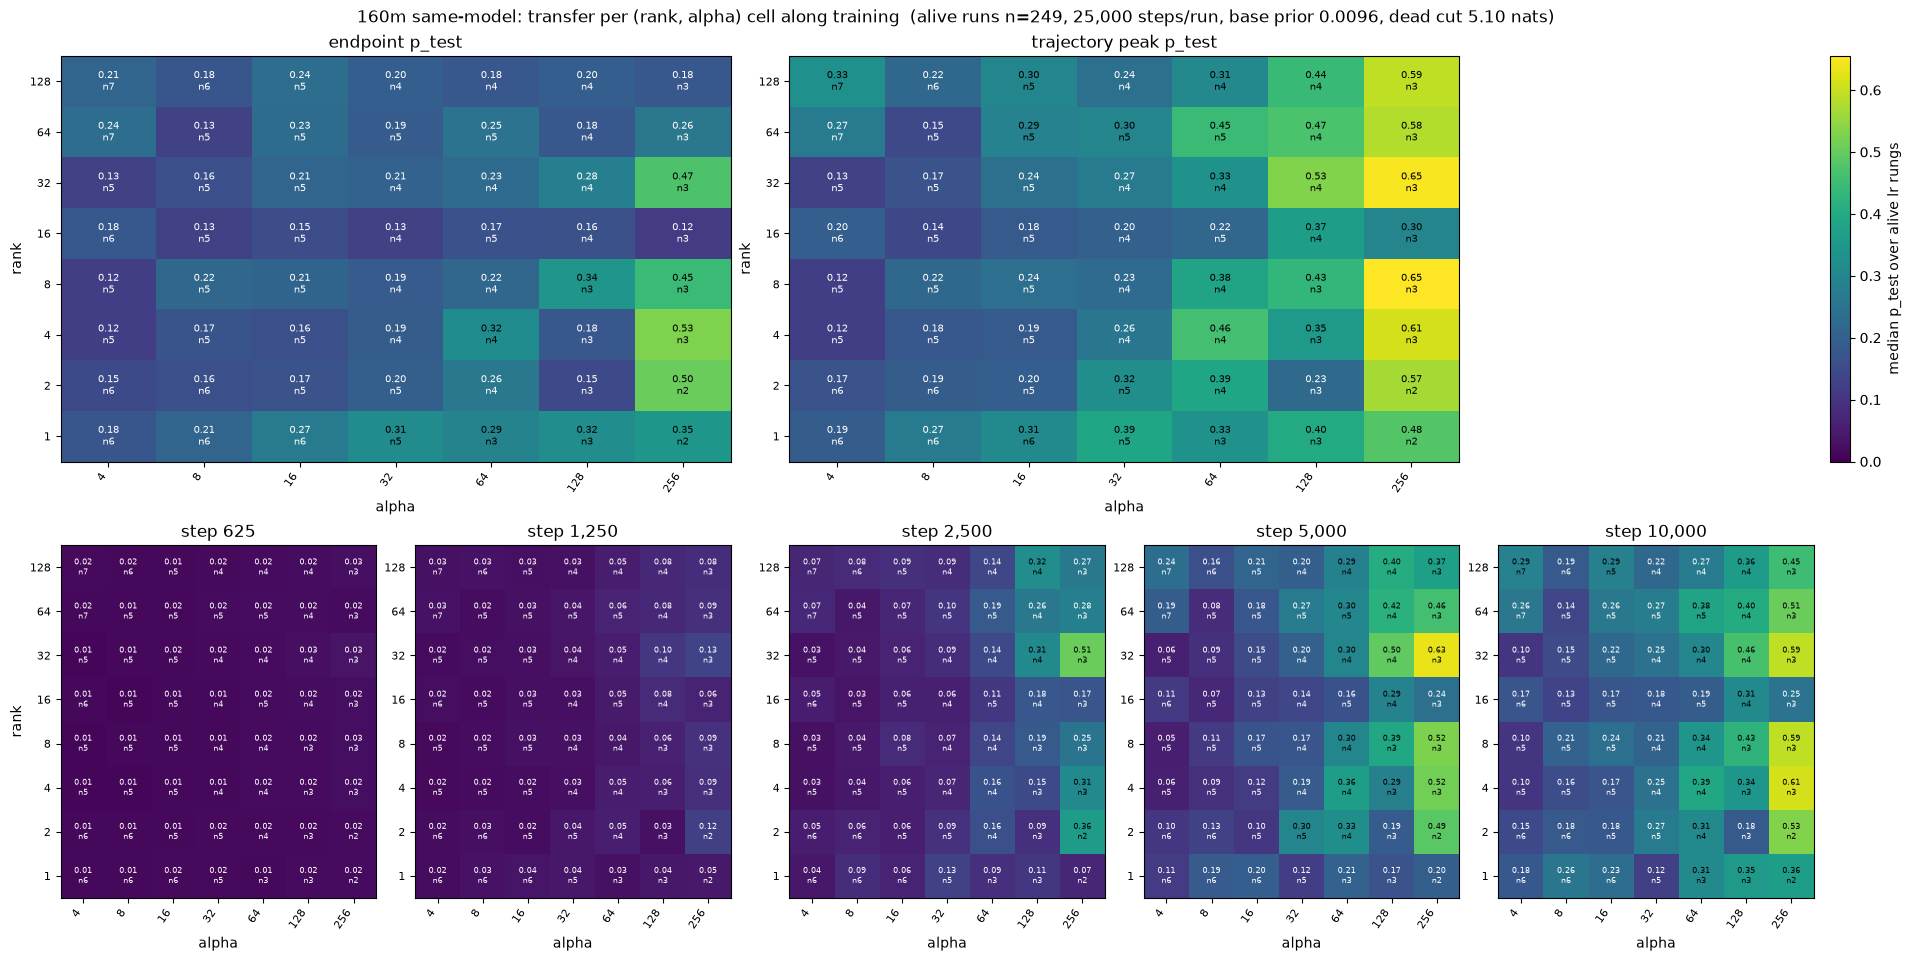

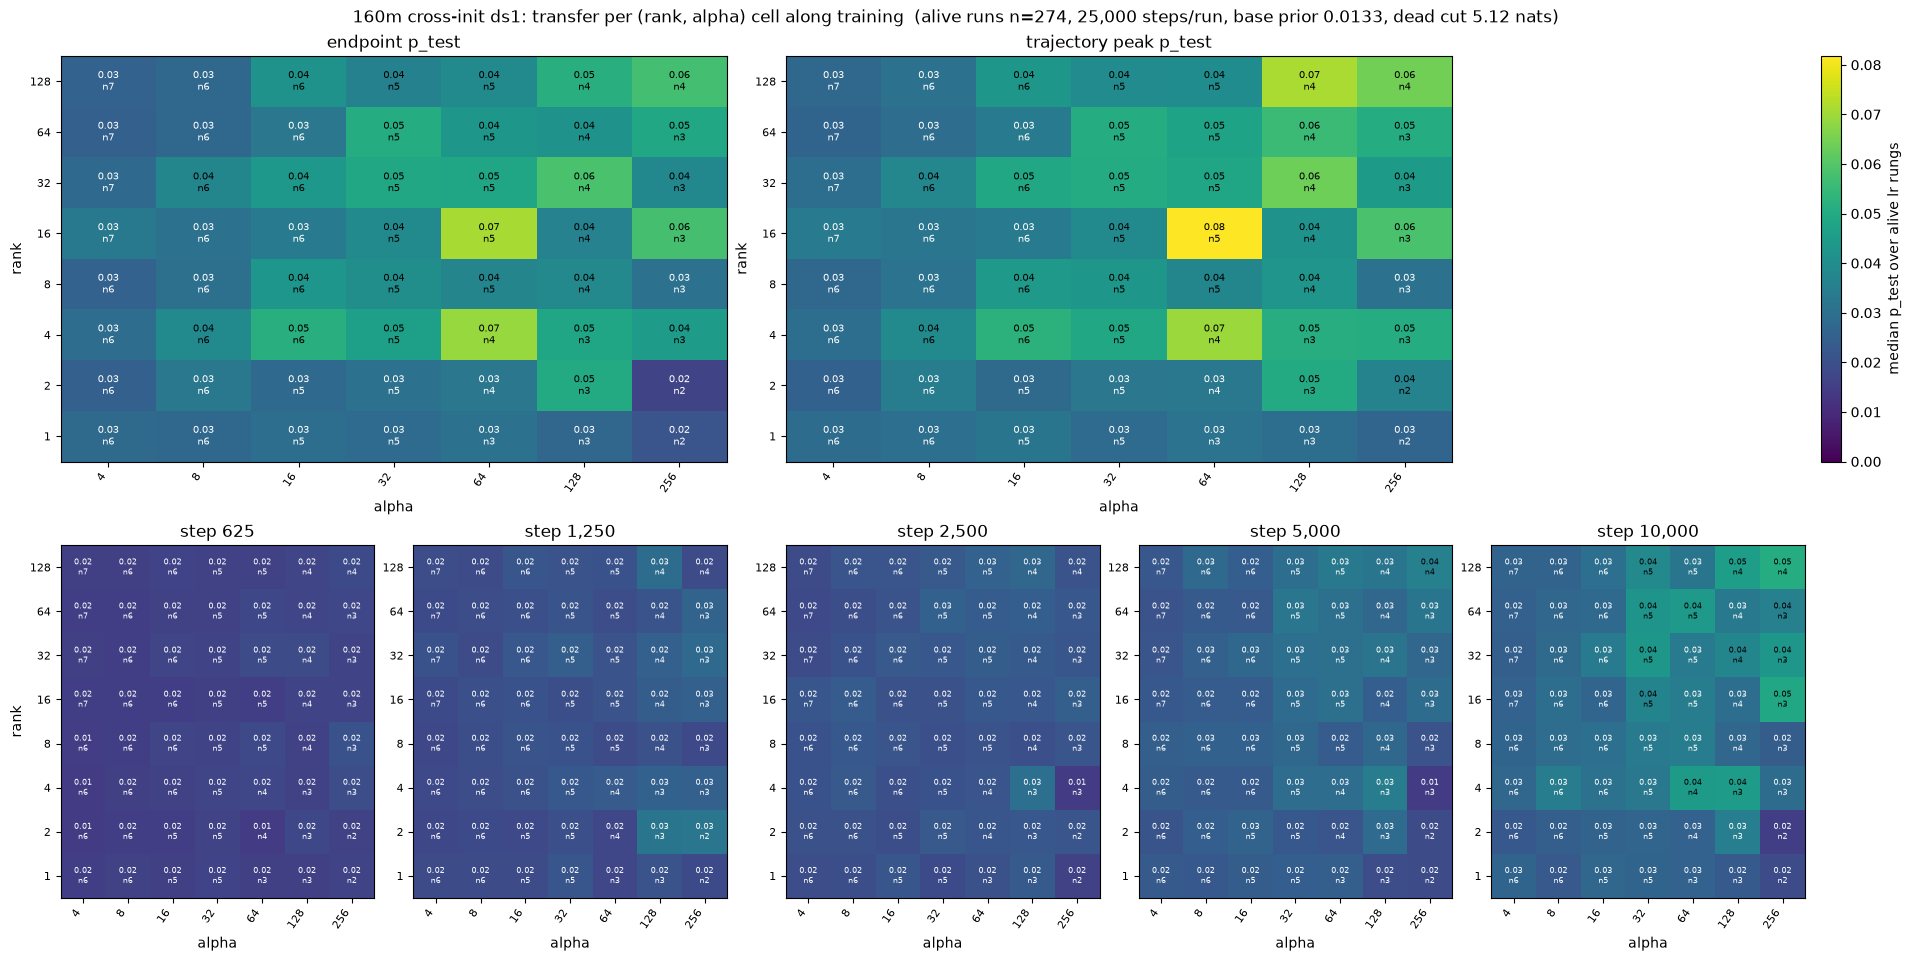

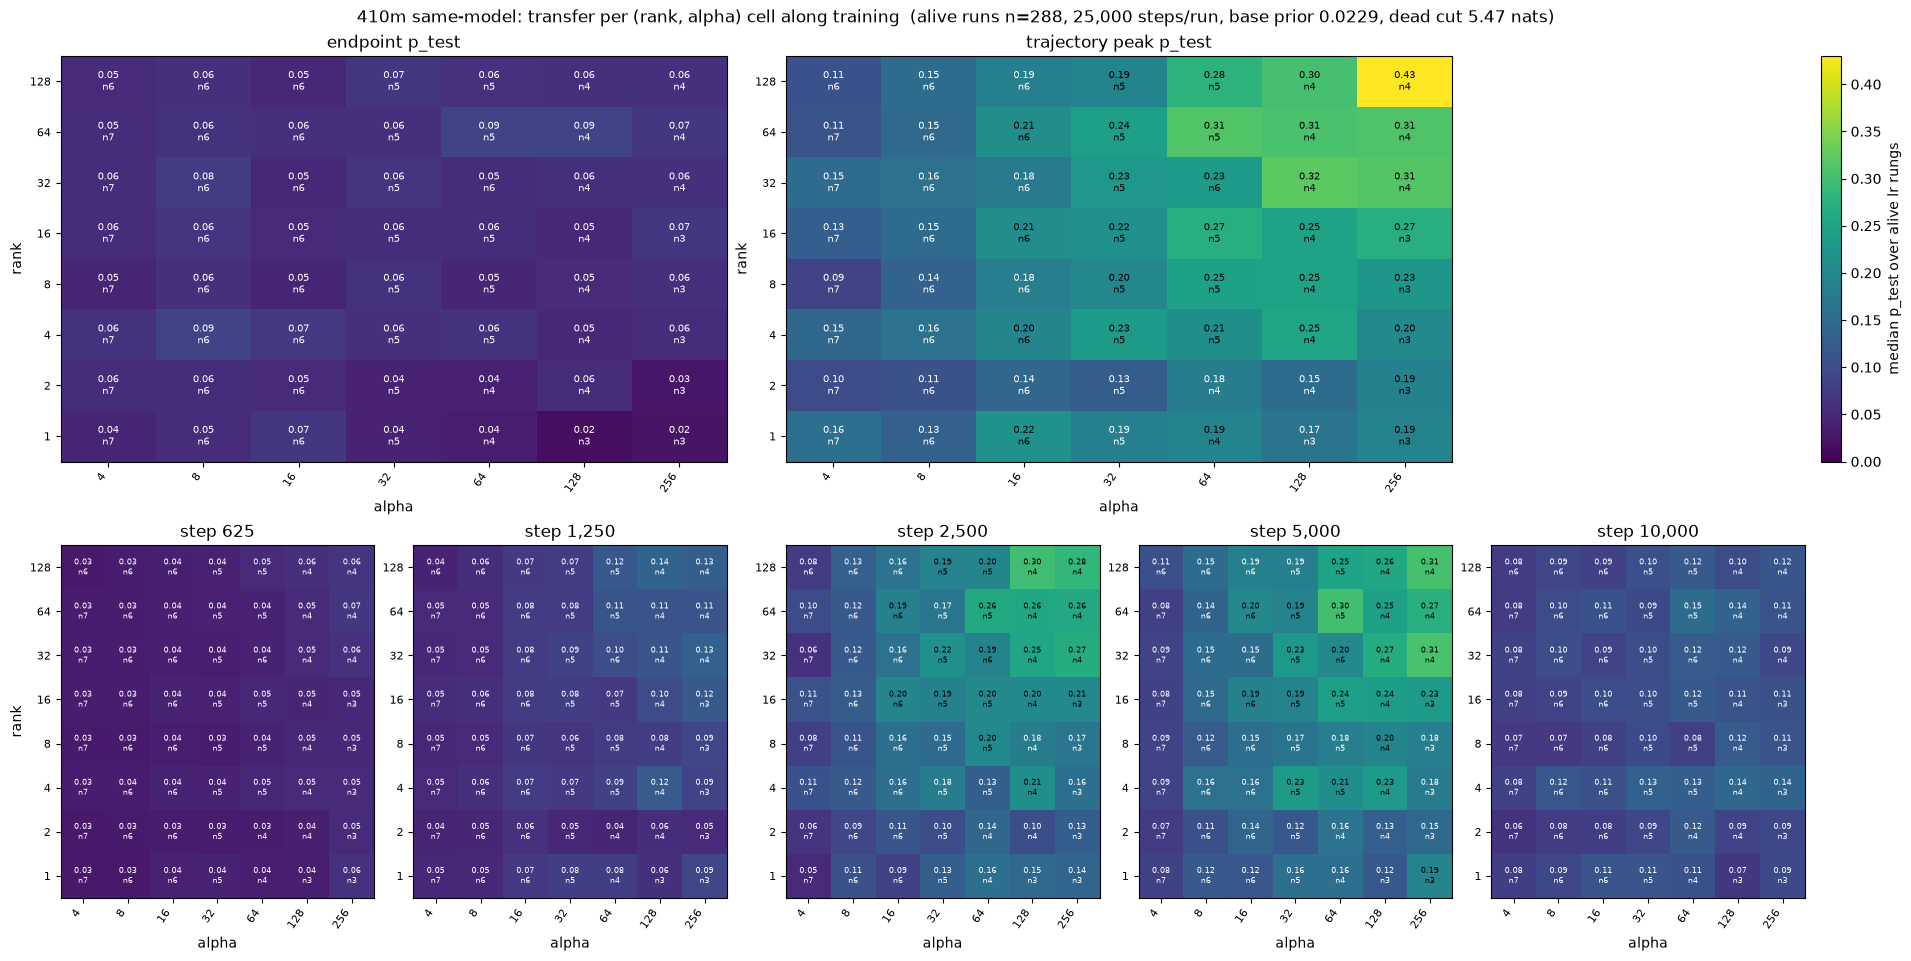

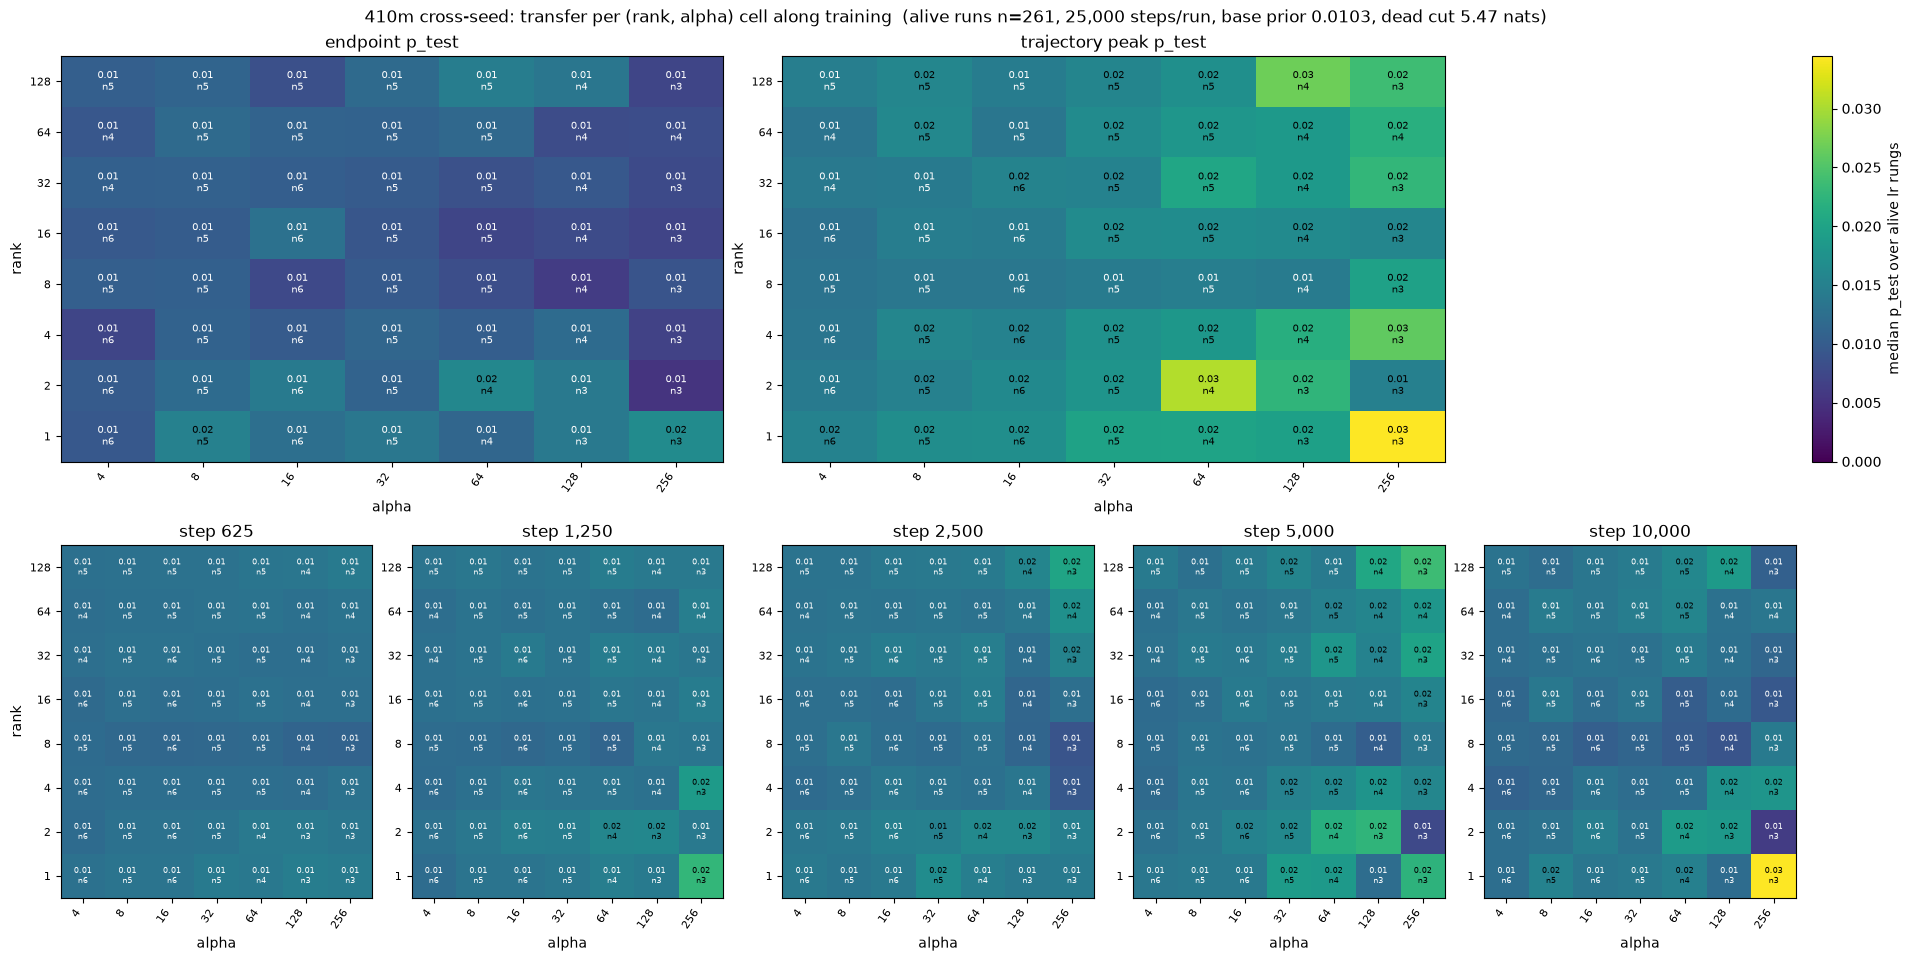

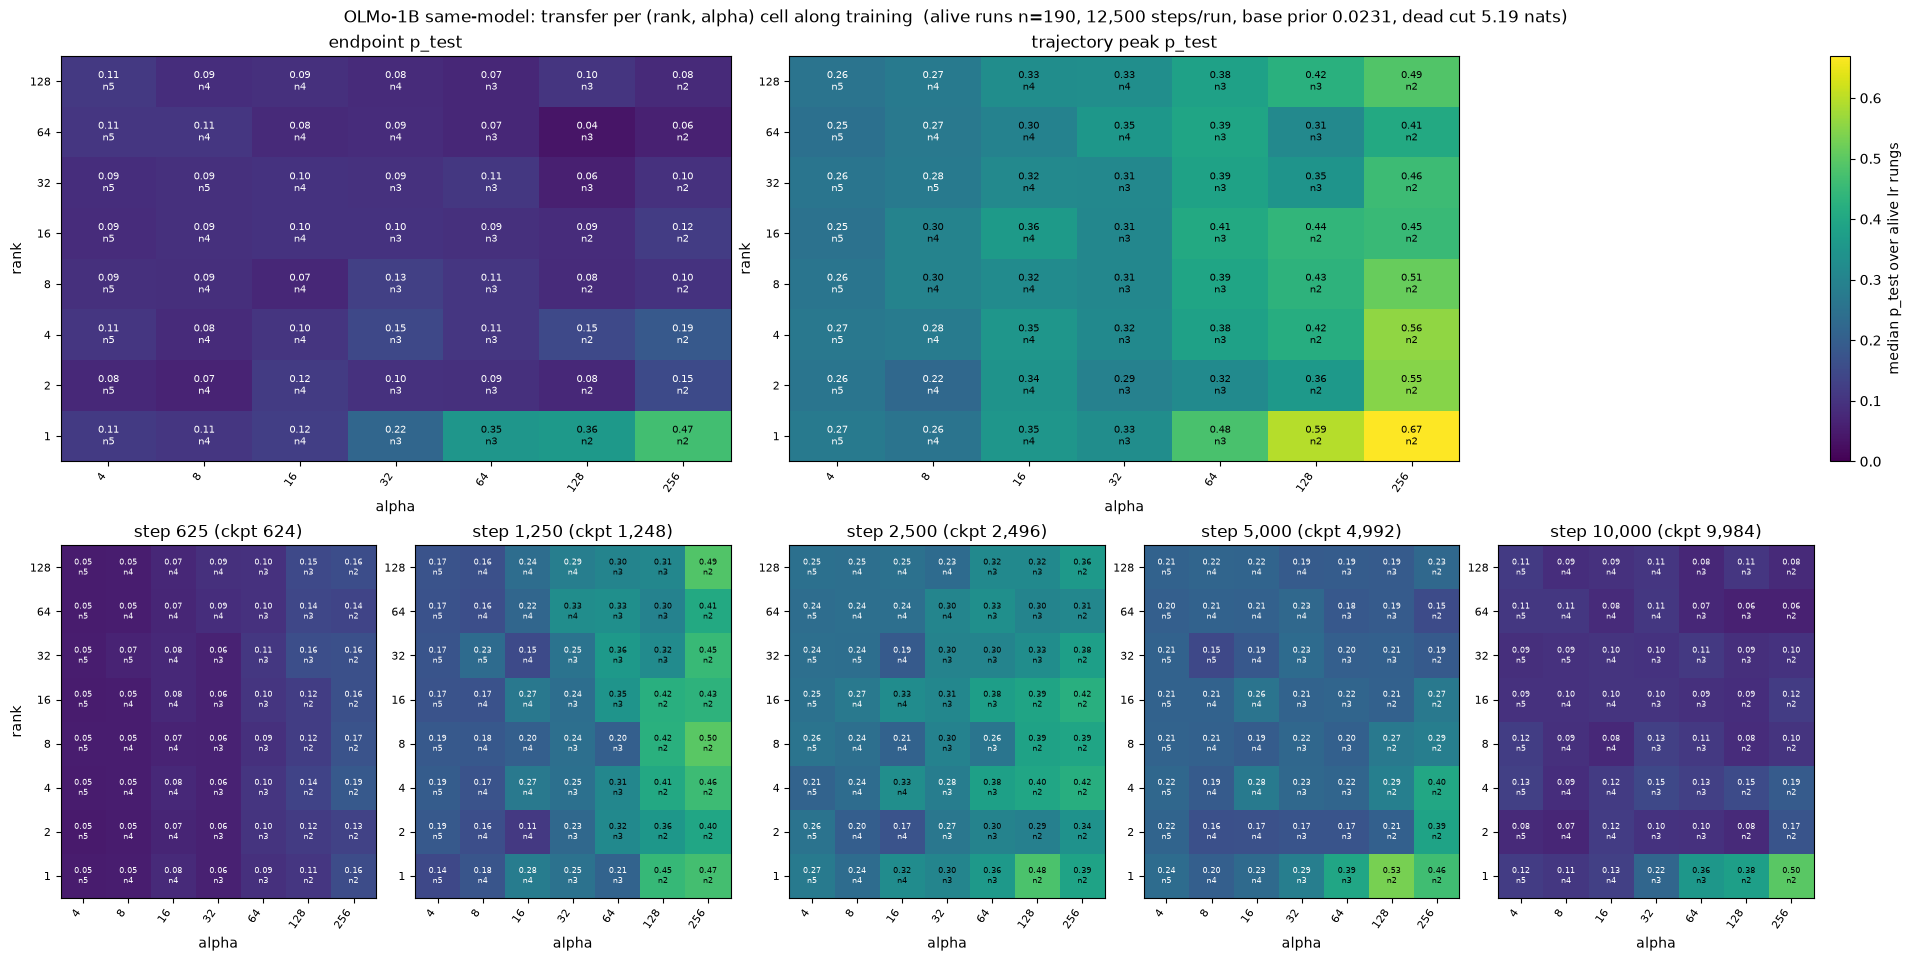

In [2]:
def _grid(sub, col):
    g = sub.pivot_table(index="rank", columns="alpha", values=col, aggfunc="median").reindex(index=RANKS, columns=ALPHAS)
    n = sub.pivot_table(index="rank", columns="alpha", values=col, aggfunc="size").reindex(index=RANKS, columns=ALPHAS)
    return g, n


def _at_step(tr, alive_tags, step):
    """Grid at the saved checkpoint nearest `step` (per run); None when no run reaches it."""
    t = tr[tr["tag"].isin(alive_tags)].copy()
    t = t[t["step"] <= 1.1 * step]
    if t.empty:
        return None, None
    t["d"] = (t["step"] - step).abs()
    pick = t.loc[t.groupby("tag")["d"].idxmin()]
    pick = pick[pick["d"] <= 0.1 * step]
    if pick.empty:
        return None, None
    return _grid(pick, "p_test"), int(pick["step"].median())


def arm_panels(arm, a, ax_grid=None):
    end, tr = a["end"], a["tr"]
    alive = end[~end["collapsed"]]
    alive_tags = set(alive["tag"])
    views = {"endpoint": _grid(alive, "p_end"), "trajectory peak": _grid(alive, "p_peak")}
    at_step = {st: _at_step(tr, alive_tags, st) for st in STEPS}
    vmax = float(np.nanmax(views["trajectory peak"][0].to_numpy()))
    fig = plt.figure(figsize=(19, 9.5), constrained_layout=True)
    gs = fig.add_gridspec(2, 5, height_ratios=[1.15, 1])
    for j, (name, (g, n)) in enumerate(views.items()):
        ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
        im = aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=7)
        ax.set_xlabel("alpha"); ax.set_ylabel("rank"); ax.set_title(f"{name} p_test")
    cax = fig.add_subplot(gs[0, 4]); cax.axis("off")
    fig.colorbar(im, ax=cax, fraction=0.5, label="median p_test over alive lr rungs")
    for j, st in enumerate(STEPS):
        gn, got = at_step[st]
        ax = fig.add_subplot(gs[1, j])
        if gn is None:
            ax.axis("off"); ax.set_title(f"step {st:,}: beyond this arm's run"); continue
        g, n = gn
        aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=6)
        ax.set_xlabel("alpha"); ax.set_ylabel("rank" if j == 0 else "")
        ax.set_title(f"step {st:,}" + ("" if got == st else f" (ckpt {got:,})"))
    fig.suptitle(f"{arm}: transfer per (rank, alpha) cell along training  "
                 f"(alive runs n={len(alive)}, {int(end['n_train_steps'].median()):,} steps/run, "
                 f"base prior {a['prior']:.4f}, dead cut {a['cut']:.2f} nats)")
    plt.show()
    return views, at_step


PANELS = {arm: arm_panels(arm, a) for arm, a in ARMS.items()}

## 3. Summary across arms

Row unit: one arm.  `grid median` = median over the 56 cells of the cell medians (so every
(rank, alpha) pair counts once regardless of how many rungs survive there).  `rank-1 / other`
= the same statistic restricted to the rank-1 row versus the other seven rows.  `step N` =
grid median at the saved checkpoint nearest step N (blank where the arm's runs are shorter).
`total steps` = the arm's run length.  `peak step (med)` = median over alive runs of the
optimizer step of their best score.  `peak / end` = median over alive runs of best score
divided by endpoint score.

In [3]:
def _gm(g, rows=None):
    v = g if rows is None else g.loc[rows]
    return float(np.nanmedian(v.to_numpy()))

rows = []
for arm, a in ARMS.items():
    end = a["end"]; alive = end[~end["collapsed"]]
    views, at_step = PANELS[arm]
    r = {"arm": arm, "alive": len(alive), "prior": round(a["prior"], 4),
         "total steps": int(alive["n_train_steps"].median())}
    for st in STEPS:
        gn, _ = at_step[st]
        r[f"step {st}"] = round(_gm(gn[0]), 3) if gn is not None else np.nan
    r["endpoint"] = round(_gm(views["endpoint"][0]), 3)
    r["peak"] = round(_gm(views["trajectory peak"][0]), 3)
    r["peak step (med)"] = int(alive["peak_step"].median())
    r["peak/end (med)"] = round(float((alive["p_peak"] / alive["p_end"].clip(lower=1e-6)).median()), 2)
    r["rank-1 end"] = round(_gm(views["endpoint"][0], [1]), 3)
    r["other end"] = round(_gm(views["endpoint"][0], [x for x in RANKS if x != 1]), 3)
    r["rank-1 peak"] = round(_gm(views["trajectory peak"][0], [1]), 3)
    r["other peak"] = round(_gm(views["trajectory peak"][0], [x for x in RANKS if x != 1]), 3)
    rows.append(r)
SUMMARY = pd.DataFrame(rows).set_index("arm")
display(SUMMARY)

# Same numbers in units of the receiver's base prior, so arms with different priors compare.
rel = SUMMARY.copy()
STEP_COLS = [f"step {st}" for st in STEPS]
for c in STEP_COLS + ["endpoint", "peak", "rank-1 end", "other end", "rank-1 peak", "other peak"]:
    rel[c] = (SUMMARY[c] / SUMMARY["prior"]).round(1)
print("same table in units of the receiver's base prior (x prior):")
display(rel.drop(columns=["prior", "peak step (med)", "peak/end (med)"]))

,alive,prior,total steps,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,peak step (med),peak/end (med),rank-1 end,other end,rank-1 peak,other peak
arm,,,,,,,,,,,,,,,,
160m same-model,249,0.0096,25000,0.015,0.032,0.086,0.194,0.252,0.195,0.294,11250,1.16,0.294,0.190,0.334,0.269
160m cross-init ds1,274,0.0133,25000,0.016,0.020,0.022,0.025,0.029,0.037,0.038,18750,1.02,0.028,0.039,0.030,0.040
410m same-model,288,0.0229,25000,0.039,0.073,0.157,0.165,0.100,0.056,0.194,5000,3.68,0.042,0.057,0.185,0.199
410m cross-seed,261,0.0103,25000,0.013,0.013,0.014,0.014,0.013,0.010,0.016,5000,1.69,0.014,0.010,0.020,0.016
OLMo-1B same-model,190,0.0231,12500,0.077,0.253,0.300,0.211,0.101,0.096,0.329,3120,2.71,0.222,0.094,0.351,0.327


same table in units of the receiver's base prior (x prior):


,alive,total steps,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,rank-1 end,other end,rank-1 peak,other peak
arm,,,,,,,,,,,,,
160m same-model,249,25000,1.6,3.3,9.0,20.2,26.3,20.3,30.6,30.6,19.8,34.8,28.0
160m cross-init ds1,274,25000,1.2,1.5,1.7,1.9,2.2,2.8,2.9,2.1,2.9,2.3,3.0
410m same-model,288,25000,1.7,3.2,6.9,7.2,4.4,2.4,8.5,1.8,2.5,8.1,8.7
410m cross-seed,261,25000,1.3,1.3,1.4,1.4,1.3,1.0,1.6,1.4,1.0,1.9,1.6
OLMo-1B same-model,190,12500,3.3,11.0,13.0,9.1,4.4,4.2,14.2,9.6,4.1,15.2,14.2


## 4. Grid-median trajectory per arm (exported)

Left: the grid median of the cell medians at each step target and at the endpoint (drawn at
the arm's own run length), in units of the receiver's base prior, one line per arm; the star
sits at the arm's median peak step.  Right: the rank-1 versus other-rank split at endpoint and
peak.

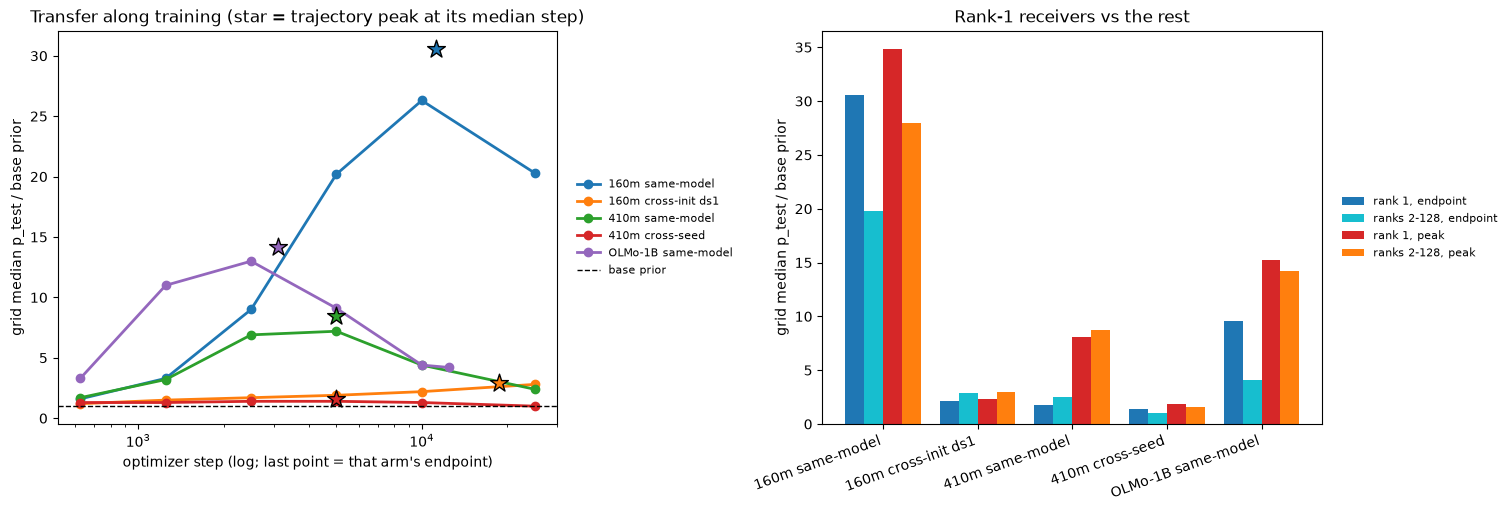

In [4]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
pal = aplots.palette(list(ARMS), cmap="tab10")
ax = axes[0]
for arm in ARMS:
    n_end = int(SUMMARY.loc[arm, "total steps"])
    pts = [(st, rel.loc[arm, f"step {st}"]) for st in STEPS if st < n_end and np.isfinite(rel.loc[arm, f"step {st}"])]
    pts.append((n_end, rel.loc[arm, "endpoint"]))
    ax.plot([x for x, _ in pts], [y for _, y in pts], "o-", ms=6, lw=2, color=pal[arm], label=arm)
    ax.scatter([SUMMARY.loc[arm, "peak step (med)"]], [rel.loc[arm, "peak"]],
               marker="*", s=180, color=pal[arm], edgecolor="k", zorder=5)
ax.axhline(1, color="k", ls="--", lw=1, label="base prior")
ax.set_xscale("log")
ax.set_xlabel("optimizer step (log; last point = that arm's endpoint)"); ax.set_ylabel("grid median p_test / base prior")
ax.set_title("Transfer along training (star = trajectory peak at its median step)")
aplots.right_legend(ax, fontsize=8)
ax = axes[1]
w = 0.2; x0 = np.arange(len(ARMS))
for k, (col, lab) in enumerate([("rank-1 end", "rank 1, endpoint"), ("other end", "ranks 2-128, endpoint"),
                                ("rank-1 peak", "rank 1, peak"), ("other peak", "ranks 2-128, peak")]):
    ax.bar(x0 + (k - 1.5) * w, rel[col].to_numpy(), width=w, label=lab,
           color=["tab:blue", "tab:cyan", "tab:red", "tab:orange"][k])
ax.set_xticks(x0); ax.set_xticklabels(list(ARMS), rotation=20, ha="right")
ax.set_ylabel("grid median p_test / base prior"); ax.set_title("Rank-1 receivers vs the rest")
aplots.right_legend(ax, fontsize=8)
fig.savefig(FIG_DIR / "transfer_trajectory_grids_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Readout

Printed from the frames above.

In [5]:
for arm in ARMS:
    r, q = SUMMARY.loc[arm], rel.loc[arm]
    print(f"{arm}: alive {int(r['alive'])}, {int(r['total steps']):,} steps/run; grid median {q['step 1250']:.1f}x prior "
          f"at step 1,250 -> {q['peak']:.1f}x at peak (median peak step {int(r['peak step (med)']):,}) -> "
          f"{q['endpoint']:.1f}x at the endpoint; "
          f"peak/end {r['peak/end (med)']:.2f}; rank-1 vs other at endpoint {q['rank-1 end']:.1f}x vs {q['other end']:.1f}x.")

160m same-model: alive 249, 25,000 steps/run; grid median 3.3x prior at step 1,250 -> 30.6x at peak (median peak step 11,250) -> 20.3x at the endpoint; peak/end 1.16; rank-1 vs other at endpoint 30.6x vs 19.8x.
160m cross-init ds1: alive 274, 25,000 steps/run; grid median 1.5x prior at step 1,250 -> 2.9x at peak (median peak step 18,750) -> 2.8x at the endpoint; peak/end 1.02; rank-1 vs other at endpoint 2.1x vs 2.9x.
410m same-model: alive 288, 25,000 steps/run; grid median 3.2x prior at step 1,250 -> 8.5x at peak (median peak step 5,000) -> 2.4x at the endpoint; peak/end 3.68; rank-1 vs other at endpoint 1.8x vs 2.5x.
410m cross-seed: alive 261, 25,000 steps/run; grid median 1.3x prior at step 1,250 -> 1.6x at peak (median peak step 5,000) -> 1.0x at the endpoint; peak/end 1.69; rank-1 vs other at endpoint 1.4x vs 1.0x.
OLMo-1B same-model: alive 190, 12,500 steps/run; grid median 11.0x prior at step 1,250 -> 14.2x at peak (median peak step 3,120) -> 4.2x at the endpoint; peak/end 2.7

## 6. The boundary law fit on the full trajectories

Two fits per arm, both on **checkpoint-resolved** labels (a run is collapsed at step *t* iff
its own Pile-KL — dp1 ΔCE for OLMo — at that checkpoint exceeds the arm's anchored cut; a
non-finite checkpoint is dead), on every lattice run including the dead ones:

1. **Per-checkpoint refit** (as `collapse_law.md` §2c and `dd1b_same_model_ladder` §7): at each
   checkpoint, the free `(b, c)` ratios and the logistic-50 % `K*` at the arm's *endpoint*
   exponents.  Needs ≥ 8 dead and ≥ 8 alive runs at that step; separated steps are left blank.
2. **Pooled trajectory fit** (`stats.collapse_law.fit_collapse_law_trajectory`): one logistic
   regression on all (run × checkpoint) rows with `ln step` as a fourth factor, covariance
   clustered on the run.  The boundary is `lr · α^b · r^c · t^d = const`, so `d` is the exponent
   of the threshold's decline, `K*(t) ∝ t^−d` — the trajectory analogue of the 160m
   `K*(T) ∝ T^−0.45` read off per-checkpoint refits.

Row unit of the first table: one arm.  The plot shows `K*(t)` at fixed endpoint exponents,
normalized by each arm's endpoint `K*`, against the optimizer step, with the pooled
`(t / t_end)^−d` line for comparison.  Arms end at different steps (25,000 for Pythia,
12,500 for OLMo), so curves are read at absolute steps, never as a share of the run.

In [6]:
from subliminal_learning.stats import collapse_law as cl

warnings.filterwarnings("ignore")
KL_COL = {arm: ("delta_ce" if arm.startswith("OLMo") else "kl") for arm in ARMS}


def labelled_long(arm, a):
    """(run x checkpoint) rows with that checkpoint's own dead label and the run's HPs."""
    end, tr = a["end"], a["tr"]
    col = KL_COL[arm]
    t = tr.dropna(subset=[col]).copy()
    if "lr" not in t:
        t = t.merge(end[["tag", "lr", "rank", "alpha"]], on="tag")
    t["collapsed"] = ((t[col] > a["cut"]) | np.isinf(t[col])).astype(int)
    t = t[t["step"] > 0]
    # A diverged run stops early and its trajectory is truncated: carry it forward as dead on
    # the arm's full step grid, so later checkpoints do not silently lose their dead runs.
    steps = np.array(sorted(t["step"].unique()))
    full = steps[steps <= np.median(t.groupby("tag")["step"].max())]
    fill = []
    for tag, last in t.groupby("tag")["step"].max().items():
        if last < full.max():
            hp = t[t["tag"] == tag].iloc[0]
            fill += [{"tag": tag, "step": st, "lr": hp["lr"], "rank": hp["rank"], "alpha": hp["alpha"],
                      col: np.inf, "collapsed": 1} for st in full[full > last]]
    if fill:
        t = pd.concat([t, pd.DataFrame(fill)], ignore_index=True)
    t["student_tag"] = t["tag"]
    return t


TRAJ_FITS, PERSTEP = {}, {}
for arm, a in ARMS.items():
    t = labelled_long(arm, a)
    # endpoint exponents for this arm (free fit on the last checkpoint of every run)
    last = t.loc[t.groupby("tag")["step"].idxmax()]
    try:
        f_end = cl.fit_collapse_law(last)
        b_end, c_end = f_end.b, f_end.c
    except Exception:
        b_end, c_end = cl.B_LAW, cl.C_LAW
    k_end = cl.kstar_logistic(last, b_end, c_end)["kstar"]
    rows = []
    for step, g in t.groupby("step"):
        row = {"step": int(step), "n": len(g), "n_dead": int(g["collapsed"].sum())}
        if g["collapsed"].nunique() == 2:
            row["kstar_fixed"] = cl.kstar_logistic(g, b_end, c_end)["kstar"]
            if row["n_dead"] >= 8 and len(g) - row["n_dead"] >= 8:
                try:
                    f = cl.fit_collapse_law(g)
                    if np.isfinite(f.b) and np.isfinite(f.c) and abs(f.b) < 5 and abs(f.c) < 5:
                        row.update(b=f.b, c=f.c)
                except Exception:
                    pass
        rows.append(row)
    PERSTEP[arm] = pd.DataFrame(rows).assign(kstar_rel=lambda d: d["kstar_fixed"] / k_end)
    try:
        TRAJ_FITS[arm] = cl.fit_collapse_law_trajectory(t)
    except Exception as exc:
        print(f"{arm}: pooled trajectory fit failed: {exc}")
    TRAJ_FITS[arm + " __meta"] = dict(b_end=b_end, c_end=c_end, k_end=k_end, n_runs=t["tag"].nunique(),
                                      n_rows=len(t), t_end=int(t["step"].max()))

tab = []
for arm in ARMS:
    m, f, ps = TRAJ_FITS[arm + " __meta"], TRAJ_FITS.get(arm), PERSTEP[arm]
    ok = ps.dropna(subset=["b"])
    first, lastrow = ps.iloc[0], ps.iloc[-1]
    tab.append({
        "arm": arm, "runs": m["n_runs"], "rows": m["n_rows"],
        "endpoint b / c": f"{m['b_end']:.3f} / {m['c_end']:.3f}", "endpoint K*": f"{m['k_end']:.2e}",
        "per-ckpt b range": f"{ok['b'].min():.2f}-{ok['b'].max():.2f}" if len(ok) else "n/a",
        "per-ckpt c range": f"{ok['c'].min():.2f}-{ok['c'].max():.2f}" if len(ok) else "n/a",
        "K*(first ckpt)/K*(end)": round(float(first["kstar_rel"]), 2) if np.isfinite(first.get("kstar_rel", np.nan)) else np.nan,
        "first / last ckpt step": f"{int(first['step']):,} / {int(lastrow['step']):,}",
        "dead at first ckpt / end": f"{int(first['n_dead'])} / {int(lastrow['n_dead'])}",
        "pooled b [CI]": f"{f.b:.3f} [{f.b_ci[0]:.2f}, {f.b_ci[1]:.2f}]" if f else "n/a",
        "pooled c [CI]": f"{f.c:.3f} [{f.c_ci[0]:.2f}, {f.c_ci[1]:.2f}]" if f else "n/a",
        "pooled d (K* ∝ t^-d) [CI]": f"{f.d:.3f} [{f.d_ci[0]:.2f}, {f.d_ci[1]:.2f}]" if f else "n/a",
        "pooled K*(end)/K*(first)": f"{f.kstar_at(lastrow['step']) / f.kstar_at(first['step']):.2f}" if f else "n/a",
    })
TAB6 = pd.DataFrame(tab).set_index("arm")
display(TAB6)

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("

,runs,rows,endpoint b / c,endpoint K*,per-ckpt b range,per-ckpt c range,K*(first ckpt)/K*(end),first / last ckpt step,dead at first ckpt / end,pooled b [CI],pooled c [CI],pooled d (K* ∝ t^-d) [CI],pooled K*(end)/K*(first)
arm,,,,,,,,,,,,,
160m same-model,479,19721,0.706 / -0.128,1.08e-03,0.64-0.72,-0.18--0.11,5.53,"625 / 25,000",109 / 230,"0.685 [0.64, 0.73]","-0.132 [-0.17, -0.09]","0.288 [0.25, 0.33]",0.35
160m cross-init ds1,464,18560,0.668 / -0.165,9.28e-04,0.61-0.72,-0.17--0.10,5.53,"625 / 25,000",64 / 190,"0.660 [0.61, 0.71]","-0.139 [-0.18, -0.10]","0.262 [0.23, 0.30]",0.38
410m same-model,461,18440,0.608 / -0.052,1.18e-03,0.55-0.64,-0.14--0.05,4.30,"625 / 25,000",66 / 174,"0.606 [0.57, 0.64]","-0.098 [-0.13, -0.07]","0.197 [0.17, 0.23]",0.48
410m cross-seed,288,11520,0.619 / -0.041,1.19e-03,0.51-0.62,-0.12--0.04,NaN,"625 / 25,000",0 / 27,"0.568 [0.53, 0.61]","-0.077 [-0.12, -0.04]","0.085 [0.06, 0.11]",0.73
OLMo-1B same-model,336,13776,0.490 / -0.019,5.08e-03,0.48-0.51,-0.06--0.01,3.75,"312 / 12,500",50 / 146,"0.507 [0.48, 0.53]","-0.031 [-0.05, -0.01]","0.186 [0.16, 0.22]",0.50


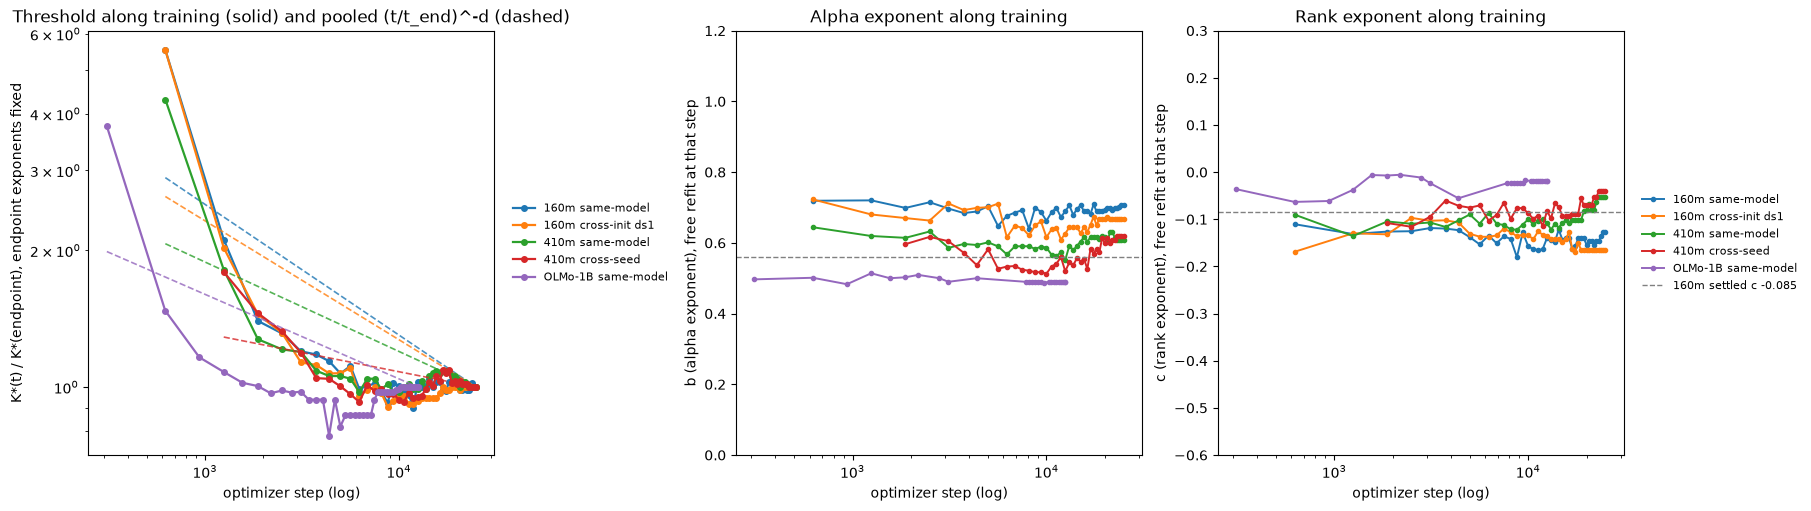

dead-count growth (runs over the cut at the saved checkpoint nearest that step; blank = beyond the arm's run):


,160m same-model,160m cross-init ds1,410m same-model,410m cross-seed,OLMo-1B same-model
optimizer step,,,,,
625,109,64,66,0,114.0
1250,180,138,130,2,136.0
1875,210,163,156,9,143.0
2500,214,170,160,11,148.0
3750,221,182,168,24,151.0
5000,227,185,170,27,153.0
7500,229,190,171,29,151.0
10000,230,193,176,32,148.0
12500,229,195,175,31,146.0


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
pal = aplots.palette(list(ARMS), cmap="tab10")
ax = axes[0]
for arm in ARMS:
    ps = PERSTEP[arm].dropna(subset=["kstar_rel"])
    ax.plot(ps["step"], ps["kstar_rel"], "o-", ms=4, lw=1.6, color=pal[arm], label=arm)
    f = TRAJ_FITS.get(arm)
    if f is not None:
        t_end = TRAJ_FITS[arm + " __meta"]["t_end"]
        st = np.geomspace(ps["step"].min(), t_end, 50)
        ax.plot(st, (st / t_end) ** (-f.d), ls="--", lw=1.2, color=pal[arm], alpha=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("optimizer step (log)"); ax.set_ylabel("K*(t) / K*(endpoint), endpoint exponents fixed")
ax.set_title("Threshold along training (solid) and pooled (t/t_end)^-d (dashed)")
aplots.right_legend(ax, fontsize=8)
ax = axes[1]
for arm in ARMS:
    ps = PERSTEP[arm].dropna(subset=["b"])
    ax.plot(ps["step"], ps["b"], "o-", ms=3, lw=1.4, color=pal[arm], label=arm)
ax.axhline(cl.B_LAW, color="gray", ls="--", lw=1, label="160m settled b 0.561")
ax.set_xscale("log"); ax.set_xlabel("optimizer step (log)"); ax.set_ylabel("b (alpha exponent), free refit at that step")
ax.set_ylim(0, 1.2); ax.set_title("Alpha exponent along training")
ax = axes[2]
for arm in ARMS:
    ps = PERSTEP[arm].dropna(subset=["c"])
    ax.plot(ps["step"], ps["c"], "o-", ms=3, lw=1.4, color=pal[arm], label=arm)
ax.axhline(cl.C_LAW, color="gray", ls="--", lw=1, label="160m settled c -0.085")
ax.set_xscale("log"); ax.set_xlabel("optimizer step (log)"); ax.set_ylabel("c (rank exponent), free refit at that step")
ax.set_ylim(-0.6, 0.3); ax.set_title("Rank exponent along training")
aplots.right_legend(ax, fontsize=8)
fig.savefig(FIG_DIR / "transfer_trajectory_grids_law_along_training.png", dpi=150, bbox_inches="tight")
plt.show()

print("dead-count growth (runs over the cut at the saved checkpoint nearest that step; blank = beyond the arm's run):")
targets = (625, 1250, 1875, 2500, 3750, 5000, 7500, 10000, 12500, 18750, 25000)
grid = {}
for arm in ARMS:
    ps = PERSTEP[arm]
    grid[arm] = {st: (int(ps.iloc[(ps["step"] - st).abs().argmin()]["n_dead"]) if st <= 1.1 * ps["step"].max() else np.nan)
                 for st in targets}
display(pd.DataFrame(grid).rename_axis("optimizer step"))